# 03 — Финальная оценка, ошибки и рекомендации

## Протокол финального теста

В этом ноутбуке фиксируем параметры, выбранные по validation в ноутбуке 02. Test используется исключительно для итоговой оценки. Global Popularity, Recent Popularity, ItemKNN и implicit ALS переобучаются на train + validation — только на событиях, случившихся до test. История для исключения уже просмотренных товаров также ограничена этим периодом.

Сравнение сохраняет train-активную когорту и фиксированный каталог выбранного режима (dev: top-1500), выбранный по train. CatBoostRanker оценивается вместе с этими моделями в ноутбуке 04, где его конфигурация выбирается только по validation.

## Метрики и cold-start

Primary metric — macro NDCG@10 с binary relevance: любой новый товар с событием в целевом интервале имеет relevance=1. Повторы и тип события не меняют цель. Recall@10 использует те же цели, Precision@10 делится на 10. Coverage — доля фиксированного каталога, рекомендованная хотя бы одному оцениваемому пользователю.

Cold-start диагностируем отдельно на всей test-части; это доли неизвестной истории/каталога, а не ranking-метрики.


## Единый протокол и режим бенчмарка

Основной протокол во всех ноутбуках — **binary relevance**: любой новый товар с будущим событием релевантен (1), независимо от типа и повторов события. Macro NDCG@10, Recall@10 и Precision@10 считаются на одинаковых пользователях с новыми целями в фиксированном каталоге; Precision всегда делится на 10. Веса 1/3/5 остаются только сигналом обучения. Graded NDCG прежнего исследования хранится в `outputs/archive/pre_binary_unification/` и не смешивается с текущими результатами.

`BENCHMARK_MODE=dev` (по умолчанию): до 20 000 пользователей / 1 500 товаров. `full`: до 100 000 / 10 000. Это расширенный ограниченный бенчмарк, а не весь каталог. Когорта и каталог выбираются только по train. Внутренний обучающий срез ранжировщика использует собственную прошлую историю и всех подходящих пользователей, как в исходном исследовании. Полный режим пишет артефакты в `outputs/full/`, сохраняя dev. До запуска full выполните `python -m scripts.run_experiments --mode full --estimate-only`: оценка использует только train. Сетки гиперпараметров не расширяются.


In [1]:
from pathlib import Path
import sys
import json
import time
import numpy as np
import pandas as pd
import gc
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 300, "savefig.dpi": 300})
from IPython.display import display, Markdown

ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents)
             if (path / "src" / "retailrocket.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open the notebook from inside the project directory.")
sys.path.insert(0, str(ROOT))
from src.benchmark import (
    get_benchmark_config, artifact_root, benchmark_manifest, validate_selection,
)
CONFIG = get_benchmark_config()
ARTIFACTS = artifact_root(ROOT, CONFIG)
PROCESSED = ROOT / "data" / "processed"
FIGURES = ARTIFACTS / "figures"
METRICS = ARTIFACTS / "metrics"
FIGURES.mkdir(parents=True, exist_ok=True)
METRICS.mkdir(parents=True, exist_ok=True)

from src.recommendation import (
    PopularityRecommender, RecentPopularityRecommender,
    ItemKNNRecommender, ImplicitLibraryALSRecommender,
    build_interaction_data, select_benchmark_users, select_catalog_items,
)
from src.evaluation import evaluate_recommender
from src.retailrocket import load_processed_events

with (METRICS / "selected_model_params.json").open() as file:
    selected_parameters = json.load(file)

train = load_processed_events(PROCESSED / "train.csv")
validation = load_processed_events(PROCESSED / "validation.csv")
validation_results = pd.read_csv(METRICS / "model_validation_metrics.csv", index_col="model")
best_validation_model = validation_results["ndcg@10"].idxmax()

MIN_HISTORY = CONFIG.min_history
MAX_USERS = CONFIG.max_users
MAX_ITEMS = CONFIG.max_items
SEED = CONFIG.seed
K = CONFIG.k
RELEVANCE_MODE = CONFIG.relevance_mode

cohort = select_benchmark_users(train, MIN_HISTORY, MAX_USERS, SEED)
catalog = select_catalog_items(train, MAX_ITEMS)
manifest = benchmark_manifest(train, cohort, catalog, CONFIG)
validate_selection(selected_parameters, manifest)
# Configuration is fixed and verified before loading held-out events.
test = load_processed_events(PROCESSED / "test.csv")
history = pd.concat([train, validation], ignore_index=True)
benchmark_history = history[
    history.visitorid.isin(cohort) & history.itemid.isin(catalog)
].copy()
test_benchmark = test[
    test.visitorid.isin(cohort) & test.itemid.isin(catalog)
].copy()
interaction_data = build_interaction_data(
    benchmark_history, user_ids=cohort, item_ids=catalog
)

assert train.event_time.max() < validation.event_time.min()
assert validation.event_time.max() < test.event_time.min()
assert history.event_time.max() < test.event_time.min()
print("Validation-selected model: {}".format(best_validation_model))
print("Final fit rows: {:,}; test rows in fixed benchmark: {:,}.".format(
    len(benchmark_history), len(test_benchmark)))
print("Test begins at {}; final fit ends at {}.".format(
    test.event_time.min(), history.event_time.max()))

/Users/mariatreseva/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/mariatreseva/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.4' currently installed).
  from pandas.core import (


Validation-selected model: ItemKNN
Final fit rows: 384,450; test rows in fixed benchmark: 7,081.
Test begins at 2015-08-25 22:39:44.906000+00:00; final fit ends at 2015-08-25 22:39:44.582000+00:00.


## Финальная модельная таблица

Четыре базовые и коллаборативные модели получают один и тот же доступный до test период и каталог. Здесь используется только ALS из библиотеки `implicit`; параметры взяты из validation-поиска, а не выбраны по test. Итоговая таблица CatBoostRanker приведена в ноутбуке 04.

**Гипотеза.** Выбранные на validation конфигурации сохранят полезность на следующем временном интервале. Сравниваем все четыре модели по единому binary-протоколу; test не определяет параметры.

In [2]:
models = {}
fit_seconds = {}


def fit_timed(name, factory):
    started = time.perf_counter()
    model = factory()
    fit_seconds[name] = time.perf_counter() - started
    models[name] = model
    return model

itemknn_params = selected_parameters["itemknn"]["parameters"]
als_params = selected_parameters["implicit_als"]["parameters"]

fit_timed("Global Popularity", lambda: PopularityRecommender().fit(
    benchmark_history, catalog_items=catalog))
fit_timed("Recent Popularity (14d)", lambda: RecentPopularityRecommender().fit(
    benchmark_history, as_of=test.event_time.min(), lookback_days=14,
    catalog_items=catalog))
fit_timed("ItemKNN", lambda: ItemKNNRecommender(**itemknn_params).fit(interaction_data))
fit_timed("implicit ALS", lambda: ImplicitLibraryALSRecommender(**als_params).fit(interaction_data))

test_summaries = []
test_per_user = {}
test_recommendations = {}
for name, model in models.items():
    summary, per_user, recommendations = evaluate_recommender(
        model, test_benchmark, benchmark_history, cohort, catalog, k=K, relevance_mode=RELEVANCE_MODE
    )
    summary["model"] = name
    summary["fit_seconds"] = fit_seconds[name]
    test_summaries.append(summary)
    test_per_user[name] = per_user
    test_recommendations[name] = recommendations

test_results = pd.DataFrame(test_summaries).set_index("model")
test_results = test_results.sort_values("ndcg@10", ascending=False)
test_results.to_csv(METRICS / "model_test_metrics.csv")
display(test_results.round(4))
from src.experiment_analysis import paired_metric_comparison
test_intervals = paired_metric_comparison(test_per_user, reference="ItemKNN", seed=SEED)
test_intervals.to_csv(METRICS / "model_test_paired_intervals.csv", index=False)
display(test_intervals.round(6))
pd.concat([frame.assign(model=name) for name, frame in test_per_user.items()], ignore_index=True).to_csv(METRICS / "model_test_per_user.csv", index=False)


,ndcg@10,recall@10,precision@10,coverage@10,evaluated_users,catalog_items,recommended_unique_items,fit_seconds
model,,,,,,,,
ItemKNN,0.0360,0.0535,0.0107,0.4216,1058,10000,4216,0.5636
implicit ALS,0.0317,0.0482,0.0091,0.2521,1058,10000,2521,2.5789
Global Popularity,0.0064,0.0060,0.0024,0.0034,1058,10000,34,0.0407
Recent Popularity (14d),0.0055,0.0093,0.0030,0.0024,1058,10000,24,0.0050


,model,reference,users,metric,confidence,n_bootstrap,seed,delta,ci_low,ci_high,relative_delta_pct
0,Global Popularity,ItemKNN,1058,ndcg@10,0.95,5000,42,-0.029601,-0.039426,-0.020145,-82.246891
1,Recent Popularity (14d),ItemKNN,1058,ndcg@10,0.95,5000,42,-0.030446,-0.039985,-0.021803,-84.593710
2,implicit ALS,ItemKNN,1058,ndcg@10,0.95,5000,42,-0.004311,-0.010903,0.001931,-11.979444


## Анализ качества и ошибок

Средняя метрика может скрывать пользователей, которым модель не нашла подходящих рекомендаций. Смотрим на пользовательское распределение NDCG лучшей **по validation** модели и на тестовые NDCG всех четырёх моделей. Нулевые значения сохраняются: они отражают реальные промахи, а не исключаются.

/var/folders/lz/_pckzh2s5kqft1jgsbfqwvwm0000gn/T/ipykernel_45534/80198893.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([test_per_user[name]["ndcg@10"].values for name in model_names],


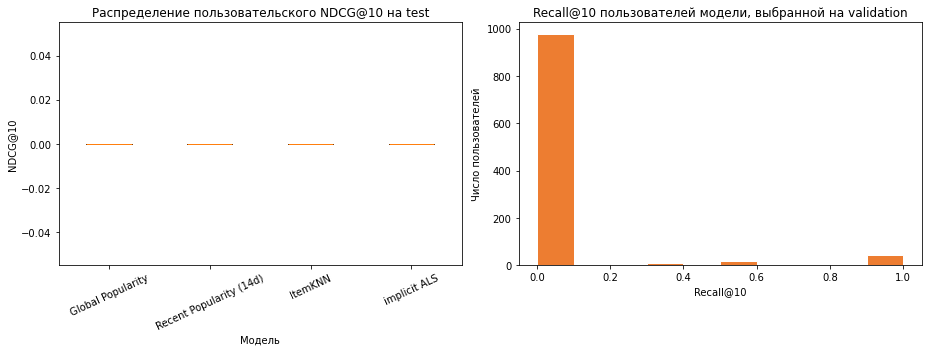

Validation выбрала ItemKNN. На test её NDCG@10=0.0360, Recall@10=0.0535, Coverage@10=0.4216.
Это финальная оценка; по test не подбирались параметры и не выбирался победитель.


**Global Popularity минус ItemKNN:** Δ=-0.02960, 95% CI [-0.03943; -0.02014]; интервал исключает ноль на этой когорте.

**Recent Popularity (14d) минус ItemKNN:** Δ=-0.03045, 95% CI [-0.03998; -0.02180]; интервал исключает ноль на этой когорте.

**implicit ALS минус ItemKNN:** Δ=-0.00431, 95% CI [-0.01090; +0.00193]; знак разницы не установлен.

Парный bootstrap фиксированных моделей не учитывает временной дрейф и зависимость пользователей через товары. По test не делаем новый выбор конфигурации.

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
model_names = list(test_per_user)
axes[0].boxplot([test_per_user[name]["ndcg@10"].values for name in model_names],
                labels=model_names, showfliers=False)
axes[0].set(title="Распределение пользовательского NDCG@10 на test",
            ylabel="NDCG@10", xlabel="Модель")
axes[0].tick_params(axis="x", rotation=25)
best_users = test_per_user[best_validation_model]
axes[1].hist(best_users["recall@10"], bins=np.linspace(0, 1, 11),
             color="#ED7D31", edgecolor="white")
axes[1].set(title="Recall@10 пользователей модели, выбранной на validation",
            xlabel="Recall@10", ylabel="Число пользователей")
fig.tight_layout()
fig.savefig(FIGURES / "test_error_analysis.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")
plt.close(fig)

print("Validation выбрала {}. На test её NDCG@10={:.4f}, Recall@10={:.4f}, Coverage@10={:.4f}.".format(
    best_validation_model,
    test_results.loc[best_validation_model, "ndcg@10"],
    test_results.loc[best_validation_model, "recall@10"],
    test_results.loc[best_validation_model, "coverage@10"]))
print("Это финальная оценка; по test не подбирались параметры и не выбирался победитель.")
for row in test_intervals.itertuples():
    conclusion = "знак разницы не установлен" if row.ci_low <= 0 <= row.ci_high else "интервал исключает ноль на этой когорте"
    display(Markdown(f"**{row.model} минус ItemKNN:** Δ={row.delta:+.5f}, 95% CI [{row.ci_low:+.5f}; {row.ci_high:+.5f}]; {conclusion}."))
display(Markdown("Парный bootstrap фиксированных моделей не учитывает временной дрейф и зависимость пользователей через товары. По test не делаем новый выбор конфигурации."))


## Cold-start: пользователи и товары

Пользователь относится к cold-start, если до начала test его нет в train + validation. Товар относится к cold-start, если он ещё не встречался в train + validation; дополнительно показываем долю тестовых событий за пределами фиксированного benchmark-каталога. Cold-start товары невозможно персонально рекомендовать моделям, построенным только на исторических взаимодействиях; для таких случаев нужны fallback-популярность или признаки контента.

In [4]:
known_users = set(history.visitorid.unique())
known_items = set(history.itemid.unique())
test_users = set(test.visitorid.unique())
test_items = set(test.itemid.unique())
cold_users = test_users - known_users
cold_items = test_items - known_items
cold_user_event_share = test.visitorid.isin(cold_users).mean()
cold_item_event_share = test.itemid.isin(cold_items).mean()
outside_catalog_event_share = (~test.itemid.isin(catalog)).mean()

cold_start = pd.DataFrame({"value": [
    len(test_users), len(cold_users), len(test_items), len(cold_items),
    cold_user_event_share, cold_item_event_share, outside_catalog_event_share,
]}, index=["unique test users", "cold test users", "unique test items",
         "cold test items", "test event share from cold users",
         "test event share from cold items", "test event share outside fixed catalog"])
display(cold_start)
print("Cold-start рассчитан по полной test-части; ranking metrics выше — только на train-активном benchmark.")

,value
unique test users,233640.000000
cold test users,212840.000000
unique test items,97556.000000
cold test items,16450.000000
test event share from cold users,0.847452
test event share from cold items,0.068623
test event share outside fixed catalog,0.625785


Cold-start рассчитан по полной test-части; ranking metrics выше — только на train-активном benchmark.


## Пример рекомендаций и интерпретация

Ниже две таблицы одного пользователя. Первая — что модель выдала в Top-10; вторая — какие новые для пользователя товары реально встретились в test. В таблице целей `recommended_in_top10=False` означает пропуск, а `recommendation_rank` показывает позицию, если товар попал в выдачу. Релевантность равна 1 для любого нового целевого товара.

In [5]:
example_model = best_validation_model
example_recommendations = test_recommendations[example_model]
example_user = None
for candidate_user, candidate_recs in example_recommendations.items():
    candidate_seen = set(benchmark_history.loc[
        benchmark_history.visitorid == candidate_user, "itemid"].astype(int))
    candidate_targets = set(test_benchmark.loc[
        test_benchmark.visitorid == candidate_user, "itemid"].astype(int)) - candidate_seen
    if candidate_targets and not candidate_targets.intersection(candidate_recs):
        example_user = candidate_user
        break
if example_user is None:
    example_user = next(iter(example_recommendations))
example_seen = set(benchmark_history.loc[
    benchmark_history.visitorid == example_user, "itemid"].astype(int))
example_targets = test_benchmark[test_benchmark.visitorid == example_user].copy()
example_targets["relevance"] = 1
example_target_relevance = example_targets.groupby("itemid")["relevance"].max().to_dict()
example_target_relevance = {
    int(item_id): value for item_id, value in example_target_relevance.items()
    if int(item_id) not in example_seen
}
example_table = pd.DataFrame({
    "rank": range(1, len(example_recommendations[example_user]) + 1),
    "itemid": example_recommendations[example_user],
})
example_table["is_test_target"] = example_table.itemid.isin(example_target_relevance)
example_table["target_relevance"] = example_table.itemid.map(example_target_relevance)
print("Рекомендации Top-10 для пользователя {}:".format(example_user))
display(example_table)

rank_by_item = {
    int(item_id): rank for rank, item_id in enumerate(
        example_recommendations[example_user], start=1)
}
target_table = pd.DataFrame([
    {"itemid": item_id, "target_relevance": relevance}
    for item_id, relevance in example_target_relevance.items()
])
target_table["recommended_in_top10"] = target_table.itemid.isin(rank_by_item)
target_table["recommendation_rank"] = target_table.itemid.map(rank_by_item)
target_table["status"] = np.where(
    target_table.recommended_in_top10, "Попал в Top-10", "Пропущен")
target_table = target_table.sort_values(
    ["recommended_in_top10", "target_relevance"], ascending=[False, False])
print("Целевые товары пользователя в test (в том числе пропущенные):")
display(target_table.reset_index(drop=True))
print("История до test: {}; новых целевых товаров в каталоге: {}; пропущено: {}.".format(
    len(example_seen), len(example_target_relevance),
    int((~target_table.recommended_in_top10).sum())))
assert set(example_recommendations[example_user]).isdisjoint(example_seen)

Рекомендации Top-10 для пользователя 1764:


,rank,itemid,is_test_target,target_relevance
0,1,400188,False,NaN
1,2,257975,False,NaN
2,3,311882,False,NaN
3,4,211210,False,NaN
4,5,153639,False,NaN
5,6,99911,False,NaN
6,7,79846,False,NaN
7,8,66737,False,NaN
8,9,272263,False,NaN
9,10,306419,False,NaN


Целевые товары пользователя в test (в том числе пропущенные):


,itemid,target_relevance,recommended_in_top10,recommendation_rank,status
0,224481,1,False,NaN,Пропущен


История до test: 4; новых целевых товаров в каталоге: 1; пропущено: 1.


## Выводы и ограничения

Validation выбирает параметры и модель; test оценивает их один раз. Coverage указывает на широту выдачи, а cold-start — на границы чисто исторической персонализации. Бенчмарк ограничен популярным каталогом и train-активной когортой, поэтому результаты нельзя переносить на холодных пользователей/товары или полный каталог без отдельного эксперимента. Числа и выводы рассчитаны по данным; параметры не выбираются по test.

## Итог full на закрытом test

Оценены 1,058 пользователей с новыми целями из фиксированного каталога. Фильтр когорты/каталога сохранил 7,081 тестовых событий; это не число уникальных релевантных пар.

Выбранный на validation ItemKNN получил test NDCG@10=0.03599, ALS — 0.03168. Пример рекомендаций и анализ ошибок используют модель, зафиксированную по validation. Общие метрики всех четырёх моделей в 04 проверены на совпадение с 02/03.

Абсолютные значения dev/full нельзя трактовать как чистое изменение качества алгоритма: в full изменились каталог, цели и оцениваемые пользователи. Итоговое сравнение ранжировщика и bootstrap приведены в 04.
